# Assignment 10: Data Science Best Practices and Final Mini Project

| | |
|---|---|
| **Student** | Lokesh Patwal |
| **Programme** | Yuva Intern - Data Science Fundamentals Assessment |
| **Assignment** | 10 of 10 |

## 2. Aim
(A) To demonstrate professional habits - clean code, documentation, modular functions, exception handling, reproducibility, privacy and project organisation. (B) To apply everything from Assignments 1-9 in one complete mini project on a real public dataset.

## 3. Objectives
1. Write readable, documented, modular code.
2. Handle errors and validate inputs.
3. Make results reproducible (seeds, fixed paths, listed versions).
4. Apply data privacy and ethical principles.
5. Organise a project folder professionally.
6. Complete a full workflow: problem, data, cleaning, EDA, statistics, charts, findings, recommendations.

## 4. Introduction and Theory
**Best practices**
* **Readable code:** meaningful names (`mean_alcohol`, not `x1`), small functions, consistent style (PEP 8), no magic numbers.
* **Documentation:** comments explain *why*; docstrings explain *what a function does*; a README explains how to run the project.
* **Modular code:** reusable functions live in `src/`, notebooks import them, and `tests/` check them.
* **Exception handling:** validate inputs and fail with a clear message.
* **Reproducibility:** fixed random seeds, relative paths, a `requirements.txt`, raw data never overwritten.
* **Privacy and ethics:** collect only what is needed, remove or pseudonymise personal identifiers, respect licences and consent, and report results honestly (including limits and uncertainty).
* **Multiple testing:** testing 13 features at the 5% level makes false alarms likely. The **Bonferroni correction** divides the threshold by the number of tests (0.05 / 13).

## 5. Software and Libraries Required
Python 3, NumPy, pandas, Matplotlib, Seaborn, SciPy, scikit-learn (only to load the dataset), and the project module `src/ds_helpers.py` (tested by `tests/test_ds_helpers.py`).

## 6. Dataset Details
**Wine Recognition dataset** - Forina, M. et al. (1991), *PARVUS: An Extendible Package for Data Exploration, Classification and Correlation*, Institute of Pharmaceutical and Food Analysis, Genoa. Available from the UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/109/wine) and bundled with scikit-learn. Please check the UCI page for the current licence terms before reusing the data.

178 wines from one region of Italy, made from 3 different grape cultivars. 13 laboratory measurements per wine:

| Column | Meaning |
|---|---|
| alcohol | alcohol (% vol) |
| malic_acid | malic acid (g/l) |
| ash, alcalinity_of_ash | ash content and its alkalinity |
| magnesium | magnesium (mg/l) |
| total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins | phenolic compounds (colour/taste related) |
| color_intensity, hue | colour measures |
| od280/od315_of_diluted_wines | protein-related optical measure |
| proline | amino acid (mg/l) |
| cultivar | grape variety (class 0, 1, 2) |

**Why it suits this project:** real laboratory data, no missing values, three groups to compare, and 13 numeric features for statistics, correlation and charts. It contains no personal data.

## 7. Step-by-Step Procedure
Part A: best-practice demonstrations (steps 1-5). Part B: mini project (steps 6-14), then validation.

## 8. Complete Python Code and 9. Expected Output
The output under each code cell is the actual output produced when this notebook was executed.

## Part A - Best practices in action

### Step 1: Reproducible setup and importing our own tested module

In [1]:
import sys
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

sys.path.insert(0, str(Path("..").resolve()))          # make `src` importable (works in Jupyter and Colab clones)
from src import ds_helpers as h

SEED = h.DEFAULT_SEED                                    # one named constant instead of a "magic number"
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
for folder in ["../visualizations", "../outputs", "../data/processed", "../data/raw"]:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Versions used for this run (record them for reproducibility):")
for name, value in [("Python", platform.python_version()), ("numpy", np.__version__), ("pandas", pd.__version__),
                    ("matplotlib", matplotlib.__version__), ("seaborn", sns.__version__), ("scipy", scipy.__version__)]:
    print(f"  {name:<11}{value}")
print("Random seed:", SEED)

Versions used for this run (record them for reproducibility):
  Python     3.13.18
  numpy      2.5.3
  pandas     3.0.5
  matplotlib 3.11.2
  seaborn    0.13.2
  scipy      1.18.1
Random seed: 42


### Step 2: Clean versus messy code (same task)

In [2]:
# BAD: unclear names, no documentation, repeated logic
def f(l):
    s = 0
    for i in l: s = s + i
    m = s / len(l)
    v = 0
    for i in l: v = v + (i - m) ** 2
    return m, (v / (len(l) - 1)) ** 0.5

# GOOD: meaningful names, docstring, validation, built on tested tools
def mean_and_sample_std(values):
    """Return (mean, sample standard deviation) of a list of numbers.

    Raises ValueError if fewer than two values are given.
    """
    if len(values) < 2:
        raise ValueError("At least two values are needed for a sample standard deviation")
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1))

sample_marks = [72, 85, 90, 66, 78]
print("messy :", f(sample_marks))
print("clean :", mean_and_sample_std(sample_marks))
assert np.allclose(f(sample_marks), mean_and_sample_std(sample_marks))
try:
    mean_and_sample_std([5])
except ValueError as error:
    print("Clear error message ->", error)

messy : (78.2, 9.654014708917737)
clean : (78.2, 9.654014708917737)
Clear error message -> At least two values are needed for a sample standard deviation


### Step 3: Exception handling and input validation with `ds_helpers`

In [3]:
for attempt in ["../data/raw/does_not_exist.csv"]:
    try:
        h.load_csv(attempt)
    except FileNotFoundError as error:
        print("FileNotFoundError handled:", error)

try:
    h.to_numeric_with_report(pd.Series(["10", "x", "30"]))
    numeric, failed = h.to_numeric_with_report(pd.Series(["10", "x", "30"]))
    print("Conversion report: converted", int(numeric.notna().sum()), "values,", failed, "failed")
except Exception as error:
    print("Unexpected:", error)

FileNotFoundError handled: CSV file not found: ../data/raw/does_not_exist.csv
Conversion report: converted 2 values, 1 failed


### Step 4: Data privacy - pseudonymisation example
If a table contains direct identifiers (name, phone, e-mail), analysts should replace them with a code and keep the lookup table separate and protected. The example uses **made-up** values only.

In [4]:
import hashlib

people = pd.DataFrame({"name": ["Example Person A", "Example Person B"], "email": ["a@example.com", "b@example.com"], "score": [71, 88]})

def pseudonymise(value, salt="project-secret-salt"):
    """Replace an identifier by a short, irreversible code (salted SHA-256)."""
    return hashlib.sha256((salt + value).encode()).hexdigest()[:10]

safe = people.assign(person_code=people["email"].map(pseudonymise)).drop(columns=["name", "email"])
display(safe)
print("Principles: collect only what you need | remove identifiers | store the salt/lookup separately | respect licence and consent | report limits honestly")

,score,person_code
0,71,0634ea4e16
1,88,f10a5bc534


Principles: collect only what you need | remove identifiers | store the salt/lookup separately | respect licence and consent | report limits honestly


**Note:** a hash with a guessable salt is *pseudonymisation*, not full anonymisation. Real projects also need legal and ethical review. The Wine data used below contains no personal data.

### Step 5: Professional project organisation (the real folder tree)

In [5]:
def show_tree(root, prefix="", skip=("__pycache__", ".ipynb_checkpoints", ".pytest_cache")):
    """Print a folder tree (folders first)."""
    entries = sorted([p for p in root.iterdir() if p.name not in skip], key=lambda p: (p.is_file(), p.name.lower()))
    for position, path in enumerate(entries):
        last = position == len(entries) - 1
        print(f"{prefix}{'└── ' if last else '├── '}{path.name}{'/' if path.is_dir() else ''}")
        if path.is_dir():
            show_tree(path, prefix + ("    " if last else "│   "))

project_root = Path("..").resolve()
print(project_root.name + "/")
show_tree(project_root)
print("\n(The README and the PDF report in reports/ are added when the whole project is finished.)")

Data_Science_Fundamentals_Assessment/
├── assignments/
│   ├── Assignment_01_Python_Basics.ipynb
│   ├── Assignment_02_Data_Types.ipynb
│   ├── Assignment_03_Functions.ipynb
│   ├── Assignment_04_NumPy.ipynb
│   ├── Assignment_05_Pandas.ipynb
│   ├── Assignment_06_Statistics.ipynb
│   ├── Assignment_07_Data_Cleaning.ipynb
│   ├── Assignment_08_EDA.ipynb
│   ├── Assignment_09_Visualization.ipynb
│   └── Assignment_10_Final_Mini_Project.ipynb
├── data/
│   ├── processed/
│   │   ├── iris_species_summary.csv
│   │   ├── stocks_yearly_mean_prices.csv
│   │   ├── students_clean.csv
│   │   └── wine_clean.csv
│   └── raw/
│       ├── iris.csv
│       ├── stocks.csv
│       ├── students_messy_synthetic.csv
│       └── wine.csv
├── outputs/
│   └── wine_feature_ranking.csv
├── reports/
├── src/
│   ├── __init__.py
│   └── ds_helpers.py
├── tests/
│   └── test_ds_helpers.py
├── visualizations/
│   ├── a10_01_class_balance.png
│   ├── a10_02_top_features_boxplots.png
│   ├── a10_03_effect_size_r

## Part B - Final mini project: What distinguishes the three wine cultivars?

### Step 6: Problem statement and objectives
**Problem statement.** A wine laboratory measures 13 chemical properties for each wine. Which measurements differ most between the three grape cultivars, and how strongly? Knowing this helps decide which measurements are worth collecting routinely.

**Objectives**
1. Load and validate the data.
2. Check data quality (missing values, duplicates, impossible values).
3. Describe the data and the class balance.
4. Test each feature for differences between cultivars with a multiple-testing correction, and measure the effect size.
5. Study correlations between features.
6. Present at least five charts, key findings and recommendations.

### Step 7: Data loading (with a safe fallback)

In [6]:
from sklearn.datasets import load_wine

WINE_PATH = Path("../data/raw/wine.csv")
try:
    wine = h.load_csv(WINE_PATH, required_columns=["alcohol", "proline", "cultivar"])
    source_note = f"read from {WINE_PATH.name}"
except FileNotFoundError:                                  # e.g. a fresh Colab session: rebuild the file from scikit-learn
    wine = load_wine(as_frame=True).frame
    wine["cultivar"] = wine.pop("target").map({0: "class_0", 1: "class_1", 2: "class_2"})
    wine.to_csv(WINE_PATH, index=False)
    source_note = "rebuilt from scikit-learn and saved to data/raw/wine.csv"

features = [c for c in wine.columns if c != "cultivar"]
print("Data", source_note, "| shape:", wine.shape, "| features:", len(features))
display(wine.head(3))

Data read from wine.csv | shape: (178, 14) | features: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0


### Step 8: Data cleaning and quality checks

In [7]:
quality = {
    "missing_cells": int(wine.isna().sum().sum()),
    "duplicate_rows": int(wine.duplicated().sum()),
    "negative_values": int((wine[features] < 0).sum().sum()),
    "non_numeric_feature_columns": [c for c in features if not pd.api.types.is_numeric_dtype(wine[c])],
    "cultivar_labels": sorted(wine["cultivar"].unique()),
}
for key, value in quality.items():
    print(f"{key:<30}{value}")

iqr_counts = {c: int(h.iqr_outlier_mask(wine[c]).sum()) for c in features}
most_outliers = sorted(iqr_counts.items(), key=lambda item: item[1], reverse=True)[:3]
print("Features with most IQR outliers:", most_outliers)

wine_clean = wine.copy()                                   # nothing needed fixing; outliers are plausible lab values, so they are KEPT
wine_clean.to_csv("../data/processed/wine_clean.csv", index=False)
print("Saved ../data/processed/wine_clean.csv", wine_clean.shape)

missing_cells                 0
duplicate_rows                0
negative_values               0
non_numeric_feature_columns   []
cultivar_labels               ['class_0', 'class_1', 'class_2']
Features with most IQR outliers: [('alcalinity_of_ash', 4), ('magnesium', 4), ('color_intensity', 4)]
Saved ../data/processed/wine_clean.csv (178, 14)


### Step 9: Exploratory data analysis

In [8]:
class_counts = wine_clean["cultivar"].value_counts().sort_index()
print(class_counts.to_string())
summary = h.describe_numeric(wine_clean[features]).round(2)
display(summary[["mean", "median", "std", "min", "max", "iqr"]])
display(wine_clean.groupby("cultivar")[["alcohol", "flavanoids", "color_intensity", "proline"]].mean().round(2))

cultivar
class_0    59
class_1    71
class_2    48


,mean,median,std,min,max,iqr
alcohol,13.00,13.05,0.81,11.03,14.83,1.32
malic_acid,2.34,1.87,1.12,0.74,5.80,1.48
ash,2.37,2.36,0.27,1.36,3.23,0.35
alcalinity_of_ash,19.49,19.50,3.34,10.60,30.00,4.30
magnesium,99.74,98.00,14.28,70.00,162.00,19.00
total_phenols,2.30,2.36,0.63,0.98,3.88,1.06
flavanoids,2.03,2.13,1.00,0.34,5.08,1.67
nonflavanoid_phenols,0.36,0.34,0.12,0.13,0.66,0.17
proanthocyanins,1.59,1.56,0.57,0.41,3.58,0.70
color_intensity,5.06,4.69,2.32,1.28,13.00,2.98


,alcohol,flavanoids,color_intensity,proline
cultivar,,,,
class_0,13.74,2.98,5.53,1115.71
class_1,12.28,2.08,3.09,519.51
class_2,13.15,0.78,7.40,629.90


### Step 10: Statistical analysis
For each feature: one-way ANOVA (are the three means equal?), the Kruskal-Wallis test (same question without assuming a normal shape) and the effect size eta squared. Because we run 13 tests, the Bonferroni threshold is 0.05 / 13.

In [9]:
alpha = 0.05 / len(features)
rows = []
for feature in features:
    groups = [part[feature].to_numpy() for _, part in wine_clean.groupby("cultivar")]
    f_stat, p_anova = stats.f_oneway(*groups)
    _, p_kruskal = stats.kruskal(*groups)
    rows.append({"feature": feature, "F": f_stat, "p_anova": p_anova, "p_kruskal": p_kruskal, "eta_squared": h.eta_squared(groups)})

ranking = pd.DataFrame(rows).sort_values("eta_squared", ascending=False).reset_index(drop=True)
ranking["significant_after_bonferroni"] = (ranking["p_anova"] < alpha) & (ranking["p_kruskal"] < alpha)
ranking.to_csv("../outputs/wine_feature_ranking.csv", index=False)
print(f"Bonferroni threshold = 0.05 / {len(features)} = {alpha:.5f}")
display(ranking.assign(p_anova=ranking["p_anova"].map("{:.1e}".format), p_kruskal=ranking["p_kruskal"].map("{:.1e}".format)).round({"F": 1, "eta_squared": 3}))
top3 = ranking["feature"].head(3).tolist()
print("Top 3 features by effect size:", top3)

Bonferroni threshold = 0.05 / 13 = 0.00385


,feature,F,p_anova,p_kruskal,eta_squared,significant_after_bonferroni
0,flavanoids,233.9,3.6e-50,4.7e-29,0.728,True
1,proline,207.9,5.8e-47,1.4e-26,0.704,True
2,od280/od315_of_diluted_wines,190.0,1.4e-44,5.7e-24,0.685,True
3,alcohol,135.1,3.3e-36,1.7e-24,0.607,True
4,color_intensity,120.7,1.2e-33,1.0e-25,0.580,True
5,hue,101.3,5.9e-30,8.5e-21,0.537,True
6,total_phenols,93.7,2.1e-28,5.0e-21,0.517,True
7,malic_acid,36.9,4.1e-14,1.4e-11,0.297,True
8,alcalinity_of_ash,35.8,9.4e-14,9.4e-14,0.290,True
9,proanthocyanins,30.3,5.1e-12,1.2e-13,0.257,True


Top 3 features by effect size: ['flavanoids', 'proline', 'od280/od315_of_diluted_wines']


### Step 11: Correlation analysis

In [10]:
corr = wine_clean[features].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
strong_pairs = upper[upper.abs() >= 0.7].sort_values(ascending=False)
print("Feature pairs with |r| >= 0.7:")
print(strong_pairs.round(3).to_string())

Feature pairs with |r| >= 0.7:
total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787


### Step 12: Visualizations (five charts)

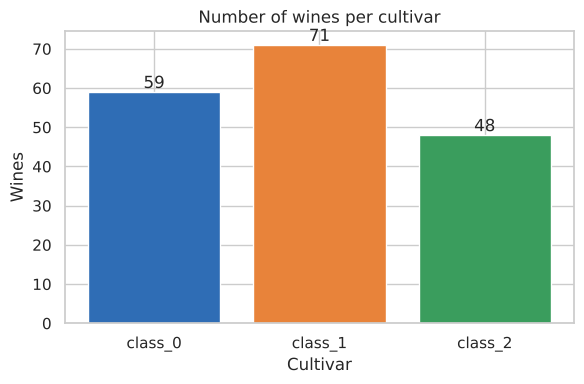

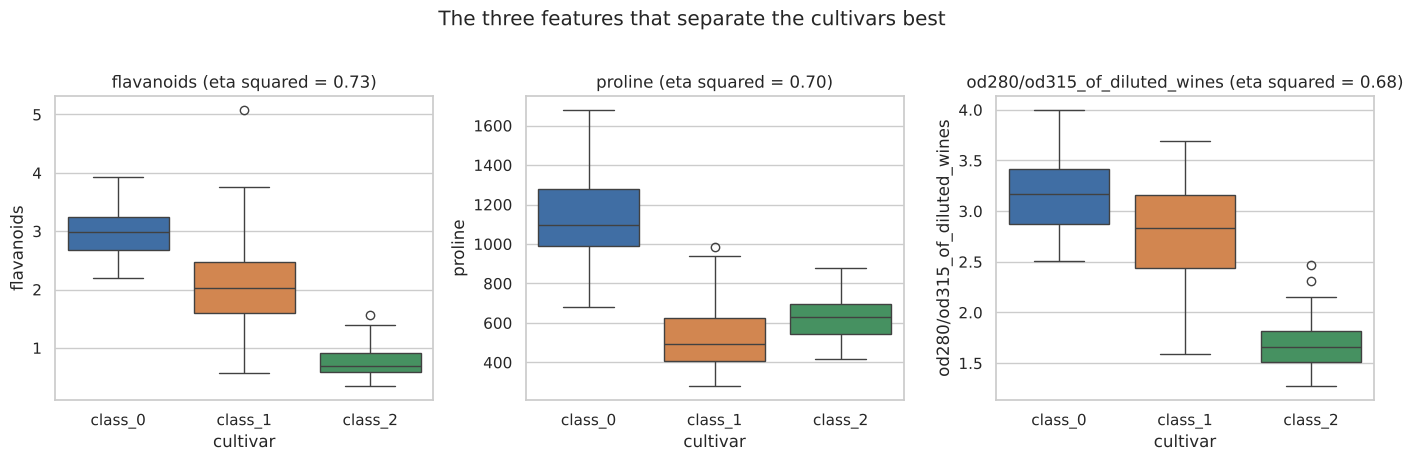

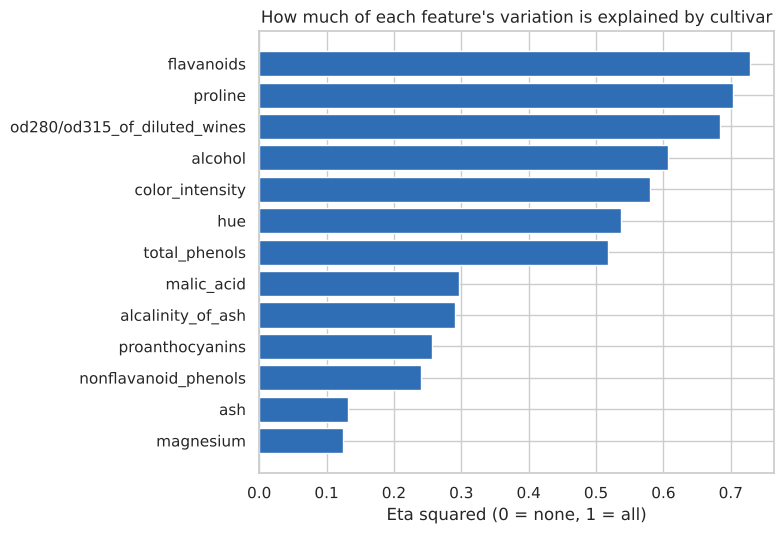

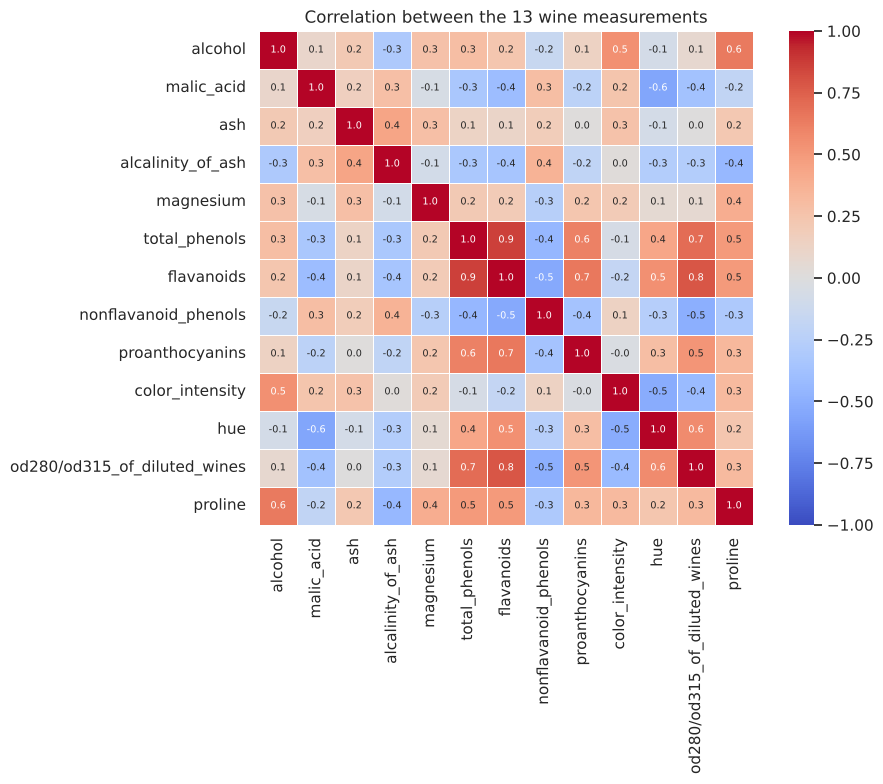

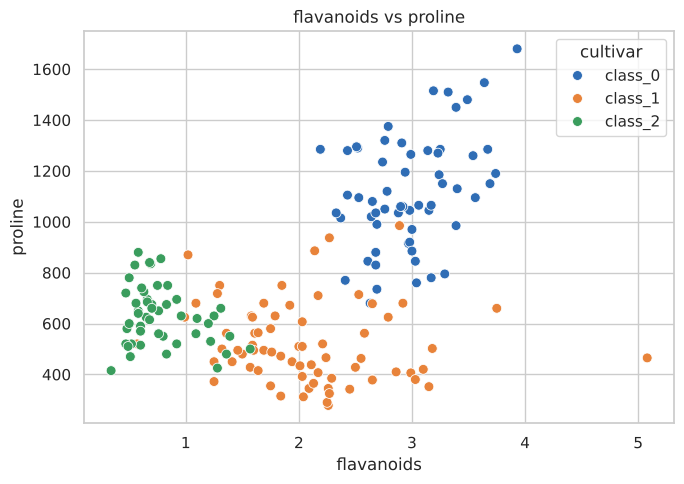

In [11]:
palette = {"class_0": "#2F6DB5", "class_1": "#E8833A", "class_2": "#3A9D5D"}

# Chart 1: class balance
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=[palette[c] for c in class_counts.index])
ax.bar_label(bars)
ax.set(title="Number of wines per cultivar", xlabel="Cultivar", ylabel="Wines")
fig.tight_layout(); fig.savefig("../visualizations/a10_01_class_balance.png", dpi=150); plt.show()

# Chart 2: box plots of the top 3 features
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, feature in zip(axes, top3):
    sns.boxplot(data=wine_clean, x="cultivar", y=feature, hue="cultivar", palette=palette, legend=False, ax=ax)
    eta = ranking.loc[ranking["feature"] == feature, "eta_squared"].iloc[0]
    ax.set_title(f"{feature} (eta squared = {eta:.2f})")
fig.suptitle("The three features that separate the cultivars best", y=1.02)
fig.tight_layout(); fig.savefig("../visualizations/a10_02_top_features_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

# Chart 3: effect size ranking
fig, ax = plt.subplots(figsize=(8, 5.5))
order = ranking.sort_values("eta_squared")
ax.barh(order["feature"], order["eta_squared"], color="#2F6DB5")
ax.set(title="How much of each feature's variation is explained by cultivar", xlabel="Eta squared (0 = none, 1 = all)", ylabel="")
fig.tight_layout(); fig.savefig("../visualizations/a10_03_effect_size_ranking.png", dpi=150); plt.show()

# Chart 4: correlation heat map
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.4, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation between the 13 wine measurements")
fig.tight_layout(); fig.savefig("../visualizations/a10_04_correlation_heatmap.png", dpi=150); plt.show()

# Chart 5: scatter of the two strongest features
fx, fy = top3[0], top3[1]
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=wine_clean, x=fx, y=fy, hue="cultivar", palette=palette, s=50, ax=ax)
ax.set(title=f"{fx} vs {fy}", xlabel=fx, ylabel=fy)
fig.tight_layout(); fig.savefig("../visualizations/a10_05_scatter_top_two.png", dpi=150); plt.show()

### Step 13: Validation checks

In [12]:
assert wine_clean.shape == (178, 14) and quality["missing_cells"] == 0
assert class_counts.sum() == 178
assert ranking["eta_squared"].between(0, 1).all() and len(ranking) == 13
assert ranking["eta_squared"].is_monotonic_decreasing
assert len(list(Path("../visualizations").glob("a10_*.png"))) == 5
assert Path("../outputs/wine_feature_ranking.csv").is_file() and Path("../data/processed/wine_clean.csv").is_file()
print("All validation checks passed.")

All validation checks passed.


## 10. Output Explanation
* **Best practices:** the messy and clean functions give identical results, but only the clean one explains itself, validates input and reports errors clearly. `load_csv` raised a clear `FileNotFoundError`, and the pseudonymisation example replaced e-mail addresses by short codes.
* **Quality:** `0` missing cells, `0` duplicate rows and `0` negative values. No cleaning was necessary, which is itself a finding. The IQR rule flags some outliers (most in `alcalinity_of_ash`: `4`); they are plausible laboratory values, so they were kept.
* **Class balance:** `{'class_0': 59, 'class_1': 71, 'class_2': 48}` - the classes are moderately balanced.
* **Statistics:** after the Bonferroni correction (threshold `0.00385`), `13` of 13 features differ significantly between cultivars. The strongest are `flavanoids` (eta squared `0.73`), `proline` (`0.70`) and `od280/od315_of_diluted_wines` (`0.68`). The weakest is `magnesium` (`0.12`).
* **Correlation:** `2` feature pair(s) have |r| of at least 0.7, the strongest being `total_phenols` with `flavanoids` (r = `0.86`).

## 11. Observations and Analysis - Key findings
1. The three cultivars differ clearly in several chemical measurements; `flavanoids, proline, od280/od315_of_diluted_wines` carry the most information about the cultivar (largest effect sizes).
2. All `13` of 13 features are statistically significant, yet their effect sizes range from `0.12` to `0.73`. Significance therefore cannot rank the features; the effect size can.
3. Some measurements are strongly correlated with each other (see the heat map), so they partly repeat the same information.
4. The data are clean, but only 178 wines from one region and one study were measured.

**Limitations.** Small sample; one region; results describe *association* with cultivar, not cause; no predictive model was built or validated here, so nothing in this notebook claims prediction accuracy.

**Recommendations**
* Prioritise the top-ranked measurements (`flavanoids, proline, od280/od315_of_diluted_wines`) if only a few laboratory tests can be afforded.
* Before building a classifier, drop or combine very highly correlated features and validate with cross-validation on separate data.
* Repeat the study on wines from other regions and years before generalising.

**Common mistakes**
| Mistake | Fix |
|---|---|
| Running many tests and trusting p < 0.05 | Apply a multiple-testing correction |
| Reporting only p-values | Add an effect size |
| Hard-coded absolute file paths | Use relative paths (works on every computer) |
| No seed | Set one and record library versions |

**Practice tasks**
1. Repeat the mini project on the Iris dataset using the same helper functions.
2. Add a `pytest` test for a new helper function.
3. Write a one-page summary for a non-technical manager.

## 12. Result / Conclusion
Part A showed professional habits (readable, validated, modular, reproducible and privacy-aware code in a clear folder structure). Part B completed a full data-science workflow on the Wine dataset: the data were validated, analysed with corrected statistical tests and effect sizes, and presented in five charts. The three cultivars differ most in `flavanoids, proline, od280/od315_of_diluted_wines`. All numbers in this notebook were computed during execution and all validation checks passed.